# ДЗ 1. Анализ продаж

Товар для анализа — 22423, REGENCY CAKESTAND 3 TIER (трёхъярусная подставка для торта). В данных ему соответствуют 2203 строки. На занятии разбирался 85123A, поэтому выбран другой товар.

Показатель продаж — количество единиц (Quantity) до возвратов. Период наблюдений: с 01.12.2010 по 09.12.2011. Агрегация: день, неделя и месяц.

Источник: [Online Retail, UCI](https://archive.ics.uci.edu/dataset/352/online+retail). Для повторного запуска нужен файл data/Online Retail.xlsx.

## 1. Загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [2]:
df = pd.read_excel("data/Online Retail.xlsx")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["StockCode"] = df["StockCode"].astype(str)
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [4]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

В исходном датасете нет пропусков в дате, количестве и коде товара. Пропущены 1454 описания и 135080 идентификаторов покупателей.

Для подсчёта продаж по коду товара CustomerID не требуется. Поэтому отсутствие идентификатора покупателя не является причиной удаления строки.

In [5]:
product = df[df["StockCode"] == "22423"].copy()
product["Description"].value_counts(dropna=False)

Description
REGENCY CAKESTAND 3 TIER    2200
damages                        2
faulty                         1
Name: count, dtype: int64

In [6]:
product.isna().sum()

InvoiceNo        0
StockCode        0
Description      0
Quantity         0
InvoiceDate      0
UnitPrice        0
CustomerID     298
Country          0
dtype: int64

In [7]:
len(product)

2203

In [8]:
product.duplicated().sum()

np.int64(11)

In [9]:
checks = pd.DataFrame()
checks["Проверка"] = ["Отмены", "Количество <= 0", "Цена <= 0"]
checks["Число строк"] = [
    product["InvoiceNo"].astype(str).str.startswith("C").sum(),
    (product["Quantity"] <= 0).sum(),
    (product["UnitPrice"] <= 0).sum()
]
checks

,Проверка,Число строк
0,Отмены,181
1,Количество <= 0,184
2,Цена <= 0,5


У выбранного товара 2203 строки. Даты, количество и описания заполнены, CustomerID отсутствует в 298 строках. Основное описание — REGENCY CAKESTAND 3 TIER, ещё три записи помечены как damages или faulty.

Найдена 181 строка с отменой, 184 строки с неположительным количеством и 5 с неположительной ценой. Эти группы пересекаются, поэтому складывать их размеры нельзя. После фильтрации остаётся 2017 строк, суммарно 13879 проданных единиц. Возвраты из этого объёма не вычитаются.

Есть 11 полных дубликатов. Они сохранены: без идентификатора позиции счёта нельзя уверенно отличить повторную позицию от ошибки выгрузки. Если это ошибки, объём продаж будет немного завышен.

In [10]:
sales = product[
    ~product["InvoiceNo"].astype(str).str.startswith("C")
    & (product["Quantity"] > 0)
    & (product["UnitPrice"] > 0)
].dropna(subset=["InvoiceDate", "Quantity"]).copy()

## 2. Продажи по дням, неделям и месяцам

In [11]:
calendar = pd.date_range(
    df["InvoiceDate"].min().normalize(),
    df["InvoiceDate"].max().normalize(),
    freq="D"
)
all_days = df["InvoiceDate"].dt.normalize().dropna().unique()
product_days = sales["InvoiceDate"].dt.normalize().unique()

coverage = pd.DataFrame(index=calendar)
coverage["Есть транзакции магазина"] = coverage.index.isin(all_days)
coverage["Есть продажи товара"] = coverage.index.isin(product_days)
coverage[~coverage["Есть транзакции магазина"]]

,Есть транзакции магазина,Есть продажи товара
2010-12-04,False,False
2010-12-11,False,False
2010-12-18,False,False
2010-12-24,False,False
2010-12-25,False,False
...,...,...
2011-11-05,False,False
2011-11-12,False,False
2011-11-19,False,False
2011-11-26,False,False


В календаре 374 дня. В 69 из них нет записей по всему магазину, в том числе во все 53 субботы. Такой рисунок согласуется с расписанием работы, но по самому файлу нельзя подтвердить причину каждого перерыва.

Для зарегистрированных продаж дни без записей заполнены нулями. Это предполагает полноту выгрузки и не означает нулевой спрос.

Недельная агрегация даёт 54 наблюдения, месячная — 13. Первая и последняя недели неполные. В декабре 2011 года есть только данные за с 1 по 9 декабря, поэтому его 450 продаж нельзя напрямую сравнивать с полными месяцами.

In [12]:
def aggregate_sales(data, calendar):
    daily = data.groupby(data["InvoiceDate"].dt.normalize())["Quantity"].sum()
    daily = daily.reindex(calendar, fill_value=0).astype(float)
    weekly = daily.resample("W-SUN").sum()
    monthly = daily.resample("MS").sum()
    return daily, weekly, monthly


daily, weekly, monthly = aggregate_sales(sales, calendar)
series = {"День": daily, "Неделя": weekly, "Месяц": monthly}

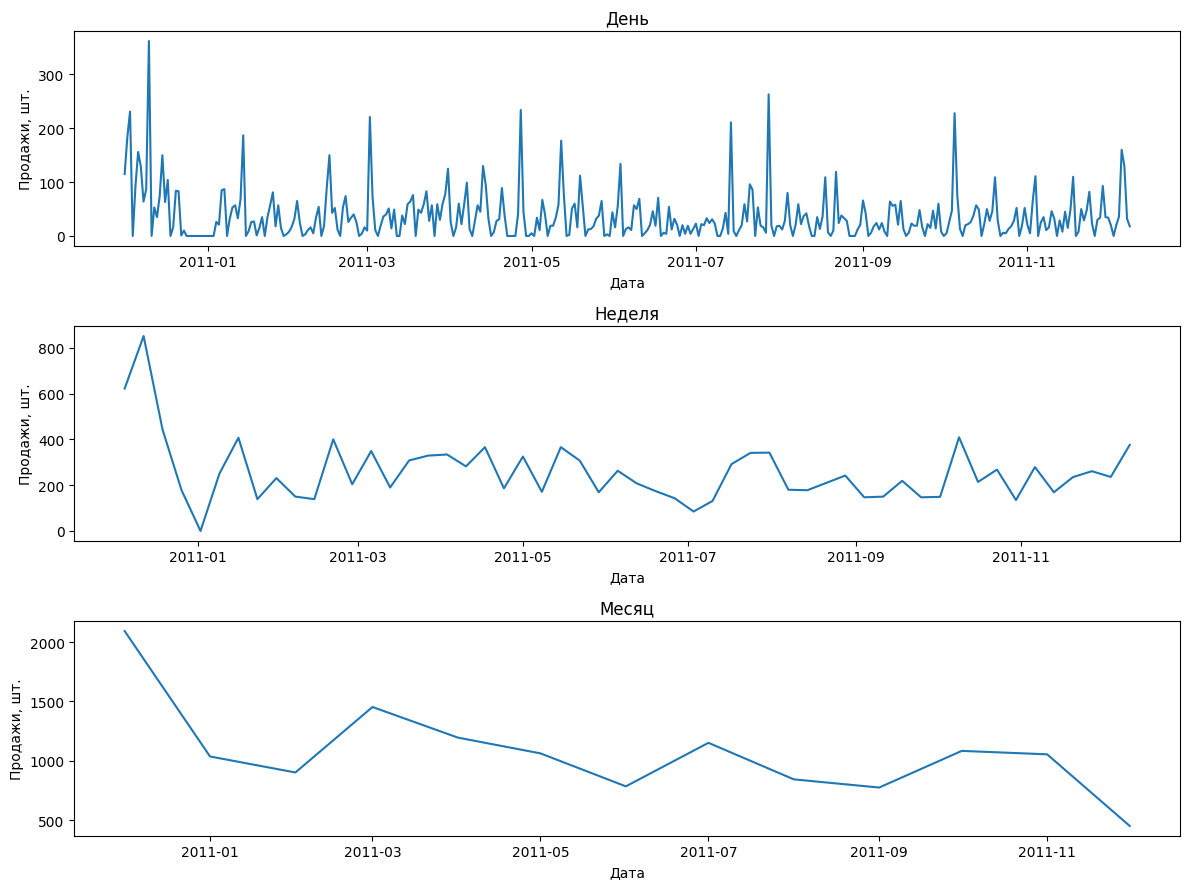

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (name, y) in zip(axes, series.items()):
    ax.plot(y)
    ax.set(title=name, xlabel="Дата", ylabel="Продажи, шт.")
plt.tight_layout()
plt.show()

## 3. Пропуски и выбросы

In [14]:
quality = pd.DataFrame()
quality["Период"] = ["День", "Неделя", "Месяц"]
quality["Наблюдения"] = [len(daily), len(weekly), len(monthly)]
quality["Пропуски"] = [daily.isna().sum(), weekly.isna().sum(), monthly.isna().sum()]
quality["Нулевые периоды"] = [(daily == 0).sum(), (weekly == 0).sum(), (monthly == 0).sum()]
quality

,Период,Наблюдения,Пропуски,Нулевые периоды
0,День,374,0,73
1,Неделя,54,0,1
2,Месяц,13,0,0


После календарного выравнивания пропусков NaN нет. Нулевые продажи встречаются в 73 днях из 374 (19,5%). Из них 69 совпадают с днями без записей всего магазина. Только в четыре дня магазин имел транзакции, но выбранный товар не продавался: 13 марта, 10 июля, 14 и 28 августа 2011 года.

На недельном уровне есть один нулевой период, на месячном — ни одного.

Потенциальные выбросы определяются по границам Q1 - 1.5 * IQR и Q3 + 1.5 * IQR. Выход за эти границы сам по себе не подтверждает ошибку.

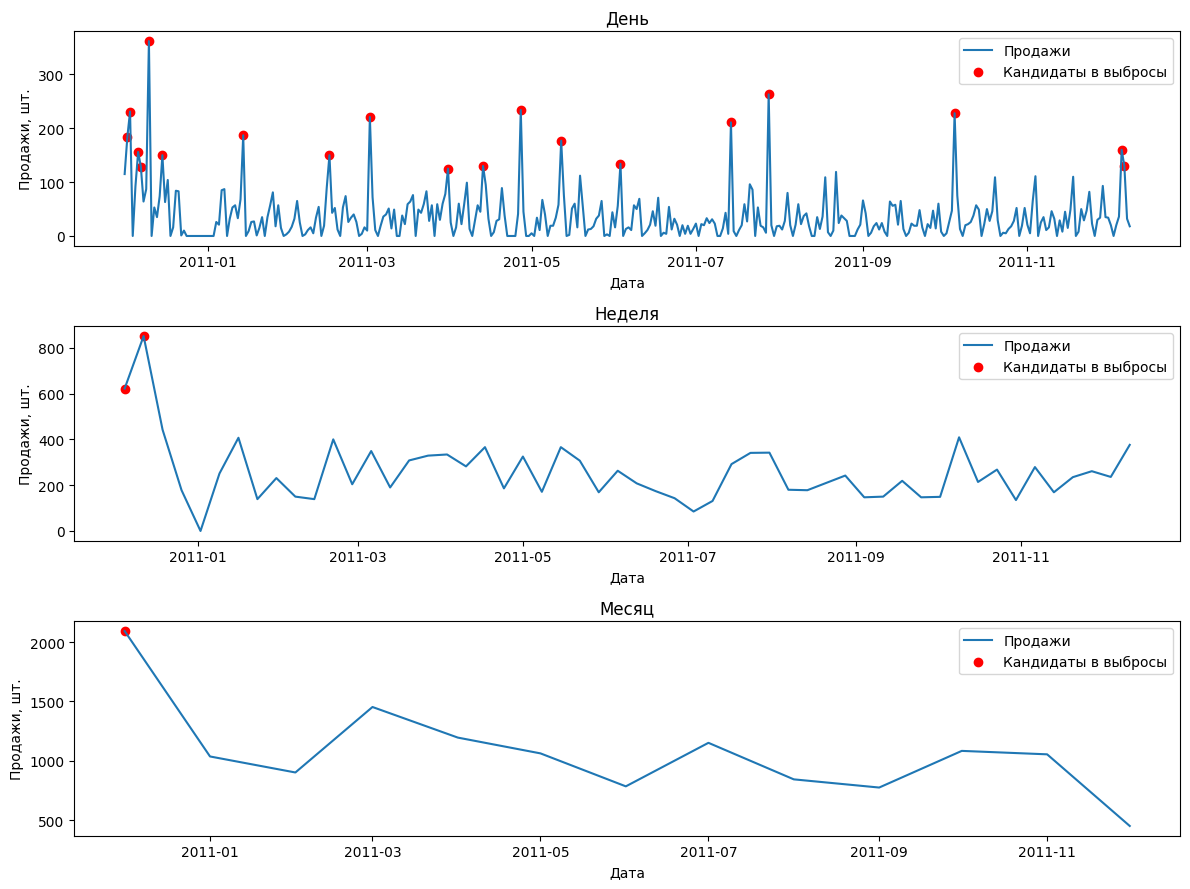

In [15]:
def find_outliers(y):
    q1, q3 = y.quantile([0.25, 0.75])
    iqr = q3 - q1
    return y[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]


fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (name, y) in zip(axes, series.items()):
    outliers = find_outliers(y)
    ax.plot(y, label="Продажи")
    ax.scatter(outliers.index, outliers, color="red", label="Кандидаты в выбросы")
    ax.set(title=name, xlabel="Дата", ylabel="Продажи, шт.")
    ax.legend()
plt.tight_layout()
plt.show()

In [16]:
outliers = pd.DataFrame()
outliers["Период"] = ["День", "Неделя", "Месяц"]
outliers["Число выбросов"] = [
    len(find_outliers(daily)),
    len(find_outliers(weekly)),
    len(find_outliers(monthly))
]
outliers

,Период,Число выбросов
0,День,19
1,Неделя,2
2,Месяц,1


In [17]:
daily.nlargest(10).to_frame("Продажи, шт.")

,"Продажи, шт."
2010-12-10,362.0
2011-07-28,263.0
2011-04-27,234.0
2010-12-03,231.0
2011-10-05,228.0
2011-03-02,221.0
2011-07-14,211.0
2011-01-14,187.0
2010-12-02,184.0
2011-05-12,177.0


По правилу IQR отмечены 19 дневных, 2 недельных и 1 месячное значение. Для дневного ряда верхняя граница равна 121 шт.; все отмеченные дни выше неё.

Максимум — 362 шт. 10 декабря 2010 года. На недельном уровне выделяются периоды с окончанием 5 и 12 декабря 2010 года (622 и 851 шт.), на месячном — декабрь 2010 года (2093 шт.). Первая из этих недель неполная, что важно учитывать при сравнении.

Эти значения сохранены. В данных об оптовой торговле крупные заказы возможны, а подтверждений ошибки нет.

## 4. Уровень и разброс продаж

In [18]:
def describe_sales(y):
    stats = y.describe()
    stats["Дисперсия"] = y.var()
    stats["CV"] = y.std() / y.mean()
    stats["IQR"] = y.quantile(0.75) - y.quantile(0.25)
    stats["Доля нулей"] = (y == 0).mean()
    return stats


stats = pd.DataFrame()
stats["День"] = describe_sales(daily)
stats["Неделя"] = describe_sales(weekly)
stats["Месяц"] = describe_sales(monthly)
stats.round(2)

,День,Неделя,Месяц
count,374.00,54.00,13.00
mean,37.11,257.02,1067.62
std,46.02,135.05,392.73
min,0.00,0.00,450.00
25%,6.00,169.50,843.00
50%,23.00,233.00,1054.00
75%,52.00,328.00,1151.00
max,362.00,851.00,2093.00
Дисперсия,2117.65,18238.47,154239.76
CV,1.24,0.53,0.37


Средние дневные продажи составляют 37,11 шт., медиана — 23 шт. Разница согласуется с влиянием крупных заказов. Стандартное отклонение — 46,02 шт., то есть разброс превышает средний уровень.

При переходе к неделям и месяцам относительные колебания становятся меньше: CV снижается с 1,24 до 0,53 и 0,37. Агрегация сглаживает отдельные пики. При этом месячных наблюдений всего 13, а последний месяц неполный, поэтому месячные статистики имеют ограниченную точность.

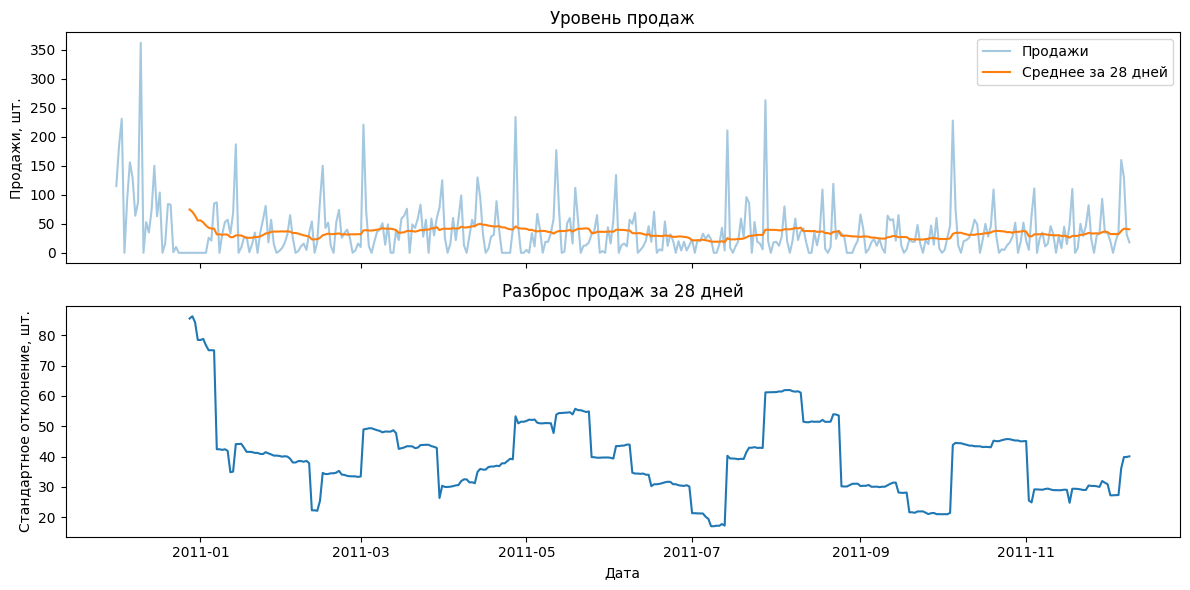

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(daily, alpha=0.4, label="Продажи")
axes[0].plot(daily.rolling(28).mean(), label="Среднее за 28 дней")
axes[0].set(title="Уровень продаж", ylabel="Продажи, шт.")
axes[0].legend()
axes[1].plot(daily.rolling(28).std())
axes[1].set(title="Разброс продаж за 28 дней", xlabel="Дата", ylabel="Стандартное отклонение, шт.")
plt.tight_layout()
plt.show()

Скользящее среднее за 28 дней меняется от 18,43 до 74,75 шт., стандартное отклонение — от 17,08 до 86,22 шт. В начале периода и уровень, и разброс выше. В течение 2011 года среднее в основном колеблется примерно в диапазоне от 20 до 50 шт.; устойчивого роста не видно.

Пики скользящего разброса совпадают с попаданием крупных заказов в окно. Поэтому считать дисперсию постоянной только по общему среднему было бы неверно.

## 5. Тренд и сезонность

В STL задан период 7 дней. Аддитивная модель допускает нули, а robust=True уменьшает влияние резких пиков на оценку компонент. Исходные продажи при этом сохраняются.

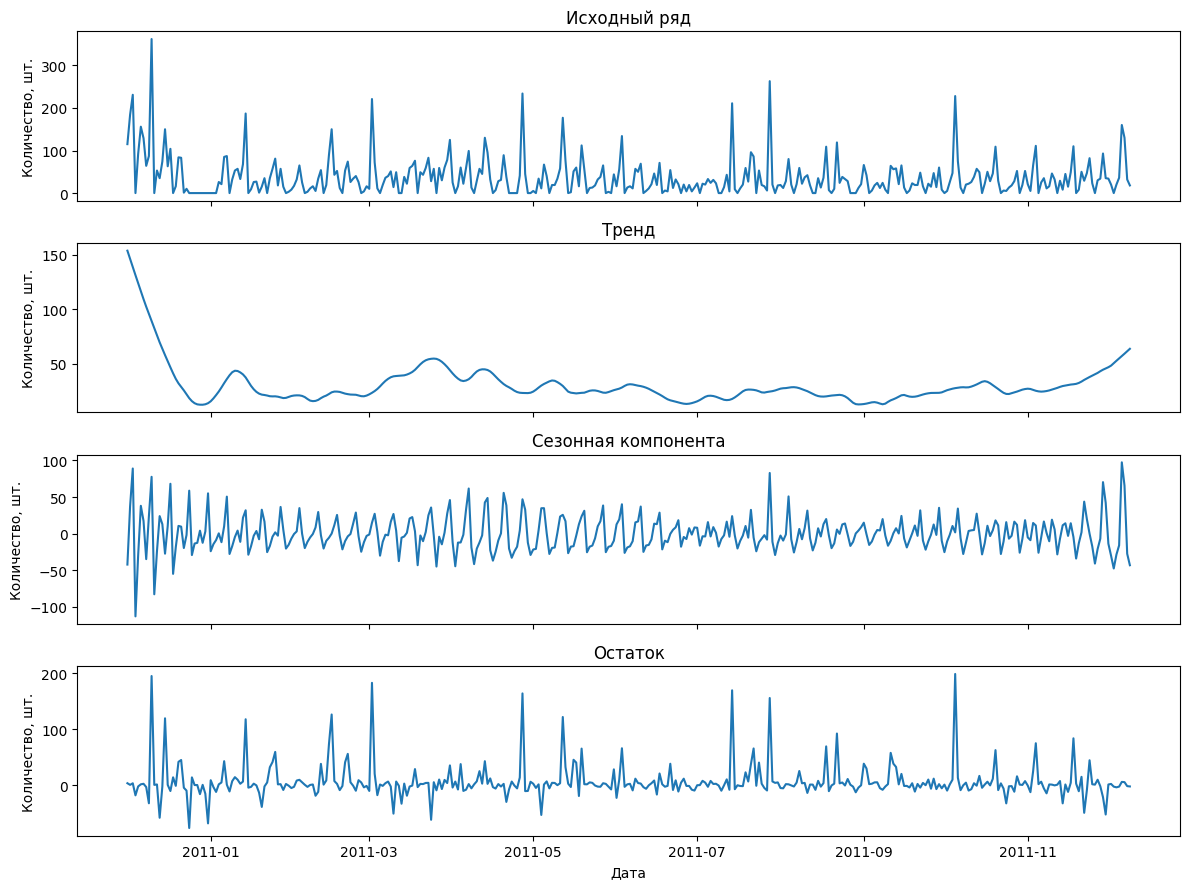

In [20]:
def decompose_sales(y, period=7):
    return STL(y, period=period, robust=True).fit()


result = decompose_sales(daily)
components = {
    "Исходный ряд": daily,
    "Тренд": result.trend,
    "Сезонная компонента": result.seasonal,
    "Остаток": result.resid
}
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (name, values) in zip(axes, components.items()):
    ax.plot(values)
    ax.set(title=name, ylabel="Количество, шт.")
axes[-1].set_xlabel("Дата")
plt.tight_layout()
plt.show()

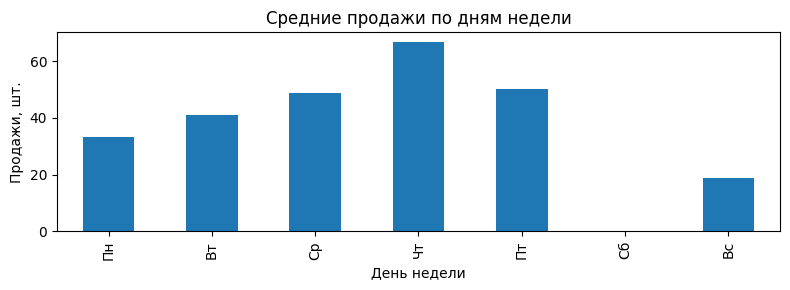

In [21]:
weekday = daily.groupby(daily.index.dayofweek).mean()
weekday.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
weekday.plot.bar(figsize=(8, 3))
plt.title("Средние продажи по дням недели")
plt.xlabel("День недели")
plt.ylabel("Продажи, шт.")
plt.tight_layout()
plt.show()

In [22]:
weekday.round(2)

Пн    33.11
Вт    40.87
Ср    48.85
Чт    66.83
Пт    50.20
Сб     0.00
Вс    18.87
Name: Quantity, dtype: float64

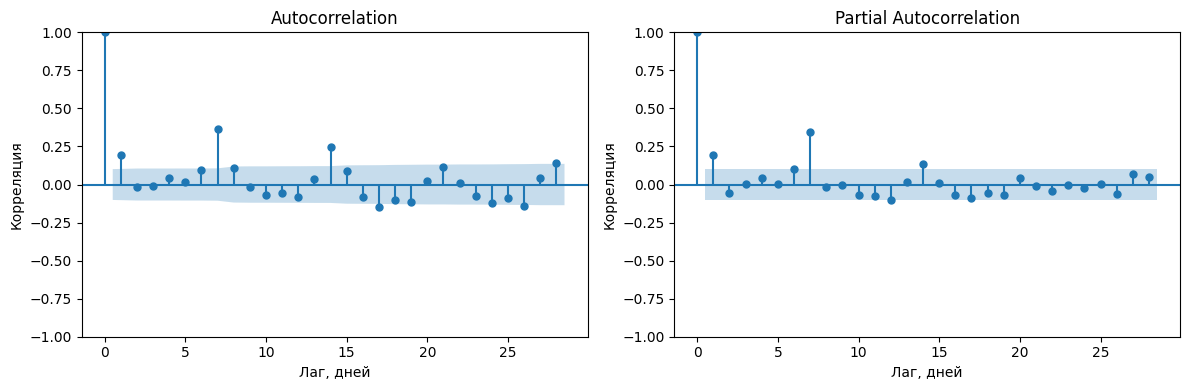

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(daily, lags=28, ax=axes[0])
plot_pacf(daily, lags=28, method="ywm", ax=axes[1])
for ax in axes:
    ax.set(xlabel="Лаг, дней", ylabel="Корреляция")
plt.tight_layout()
plt.show()

In [24]:
from statsmodels.tsa.stattools import acf

acf_values = acf(daily, nlags=28)
weekly_lags = pd.DataFrame()
weekly_lags["Лаг, дней"] = [7, 14, 21, 28]
weekly_lags["ACF"] = acf_values[[7, 14, 21, 28]]
weekly_lags.round(3)

,"Лаг, дней",ACF
0,7,0.365
1,14,0.247
2,21,0.116
3,28,0.139


Средние продажи различаются по дням недели. Максимум приходится на четверг — 66,83 шт., в воскресенье среднее составляет 18,87 шт. По субботам продаж нет, как и транзакций магазина в целом.

ACF на лагах 7 и 14 равна 0,365 и 0,247. На графике оба значения выходят за доверительные границы. На лагах 21 и 28 связь слабее — 0,116 и 0,139. Вместе с профилем дней недели это подтверждает недельный ритм зарегистрированных продаж. Его нельзя полностью приписать спросу: расписание магазина тоже влияет на результат.

STL показывает высокий начальный уровень с последующим снижением. В течение 2011 года тренд колеблется, но постоянного роста нет. Сезонная часть меняется по амплитуде, а в остатках сохраняются крупные положительные пики — недельный рисунок объясняет не все заказы. Краевые оценки тренда менее устойчивы. Для вывода о повторяющейся годовой сезонности истории недостаточно.

## 6. Стационарность

Уровень значимости равен 0,05. Нулевая гипотеза ADF предполагает наличие единичного корня, а нулевая гипотеза KPSS предполагает стационарность вокруг постоянного уровня.

Если у ADF значение p меньше 0,05, а у KPSS не меньше 0,05, результаты согласуются со стационарностью. Обратная комбинация указывает на нестационарность. При остальных сочетаниях результат неоднозначен.

In [25]:
def check_stationarity(y):
    adf_result = adfuller(y.dropna(), regression="c", autolag="AIC")
    kpss_result = kpss(y.dropna(), regression="c", nlags="auto")
    return adf_result[1], kpss_result[1]


adf_p, kpss_p = check_stationarity(daily)

stationarity = pd.DataFrame()
stationarity["Ряд"] = ["Исходный"]
stationarity["ADF p-value"] = [adf_p]
stationarity["KPSS p-value"] = [kpss_p]
stationarity

/var/folders/z4/zvpkp03d2532f8lk85p_bd580000gn/T/ipykernel_4789/4015526786.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(y.dropna(), regression="c", autolag="AIC")
/var/folders/z4/zvpkp03d2532f8lk85p_bd580000gn/T/ipykernel_4789/4015526786.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kp

,Ряд,ADF p-value,KPSS p-value
0,Исходный,4.057049e-07,0.030174


Для исходного ряда у ADF значение p меньше 0,001, а у KPSS оно равно 0,0302. Оба теста отвергают свои нулевые гипотезы. ADF отвергает наличие единичного корня, но KPSS также отвергает стационарность вокруг постоянного уровня.

Результат неоднозначен. По этим тестам нельзя уверенно назвать исходный ряд стационарным или сказать, что ему обязательно нужно дифференцирование. На графиках также меняются уровень и разброс. Первые разности рассмотрены как один из вариантов преобразования.

In [26]:
diff = daily.diff().dropna()
adf_diff_p, kpss_diff_p = check_stationarity(diff)

stationarity.loc[1] = ["Первые разности", adf_diff_p, kpss_diff_p]
stationarity

/var/folders/z4/zvpkp03d2532f8lk85p_bd580000gn/T/ipykernel_4789/4015526786.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(y.dropna(), regression="c", autolag="AIC")
/var/folders/z4/zvpkp03d2532f8lk85p_bd580000gn/T/ipykernel_4789/4015526786.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(y.dropna(), regression="c", nlags="auto")
/var/folders/z4/zvpkp03d2532f8lk85p_bd580000gn/T/ipykernel_4789/4015526786.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argumen

,Ряд,ADF p-value,KPSS p-value
0,Исходный,4.057049e-07,0.030174
1,Первые разности,3.512434e-13,0.100000


После первых разностей у ADF значение p меньше 0,001. KPSS возвращает 0,1 с предупреждением, что настоящее значение выше этой границы. При уровне значимости 0,05 результаты согласуются со стационарностью преобразованного ряда.

Первые разности можно использовать дальше. Но результаты не доказывают, что это единственный подходящий способ преобразования или что ряд стал белым шумом.

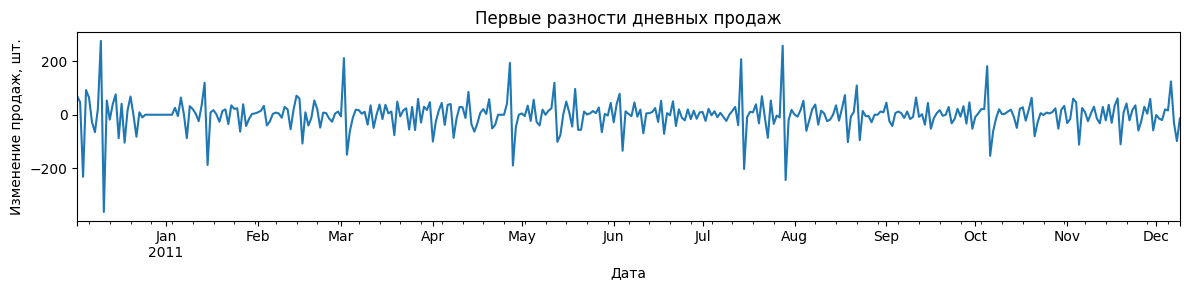

In [27]:
diff.plot(figsize=(12, 3))
plt.title("Первые разности дневных продаж")
plt.xlabel("Дата")
plt.ylabel("Изменение продаж, шт.")
plt.tight_layout()
plt.show()

## 7. Выводы

После очистки осталось 2017 строк, всего 13 879 проданных единиц. Отмены и строки с нулевым или отрицательным количеством и ценой исключены. Возвраты отдельно не вычитались. Ещё нашлось 11 одинаковых строк. Они оставлены, так как по данным нельзя точно определить, ошибка это или повторная позиция заказа.

В среднем продавалось 37,11 штуки в день, медиана составила 23. Крупные заказы заметно поднимают среднее. Максимум за день составил 362 штуки. По правилу IQR выделено 19 дневных значений, но они сохранены: большой заказ сам по себе не означает ошибку.

Продаж не было в 73 днях. В 69 из них нет записей вообще по магазину, в том числе во все субботы. Поэтому объяснять все нули отсутствием спроса нельзя.

По неделям и месяцам продажи выглядят ровнее. Коэффициент вариации снижается с 1,24 для дневного ряда до 0,53 для недельного и 0,37 для месячного. В начале периода уровень продаж и разброс выше. Дальше они меняются, но постоянного роста не видно. Последний месяц неполный, поэтому его низкий итог не говорит о падении продаж.

В данных есть недельный ритм. По четвергам в среднем продавалось около 67 штук, по воскресеньям около 19. Автокорреляция на лагах 7 и 14 дней составляет 0,365 и 0,247. Это тоже указывает на повторение внутри недели. При этом часть такого рисунка связана с отсутствием транзакций по субботам. Для оценки годовой сезонности данных недостаточно.

Тесты стационарности исходного ряда дали неоднозначный результат. ADF отвергает наличие единичного корня, а KPSS отвергает стационарность вокруг постоянного уровня. После первых разностей результаты согласуются со стационарностью: у ADF значение p меньше 0,001, у KPSS больше 0,1. Первые разности можно использовать для дальнейшего анализа, хотя их необходимость не доказана.

Ряд подходит для дальнейшего прогнозирования продаж при условии, что выгрузка полная. Нужно учитывать недельный ритм и крупные заказы.